In [1]:
import pandas as pd
df=pd.read_csv("tweet_emotions.csv")
df

,tweet_id,sentiment,content
0,1956967341,empty,@tiffanylue i know i was listenin to bad habi...
1,1956967666,sadness,Layin n bed with a headache ughhhh...waitin o...
2,1956967696,sadness,Funeral ceremony...gloomy friday...
3,1956967789,enthusiasm,wants to hang out with friends SOON!
4,1956968416,neutral,@dannycastillo We want to trade with someone w...
...,...,...,...
39995,1753918954,neutral,@JohnLloydTaylor
39996,1753919001,love,Happy Mothers Day All my love
39997,1753919005,love,Happy Mother's Day to all the mommies out ther...
39998,1753919043,happiness,@niariley WASSUP BEAUTIFUL!!! FOLLOW ME!! PEE...


In [2]:
df.isna().sum()

tweet_id     0
sentiment    0
content      0
dtype: int64

In [3]:
df["sentiment"].value_counts()

neutral       8638
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
empty          827
enthusiasm     759
boredom        179
anger          110
Name: sentiment, dtype: int64

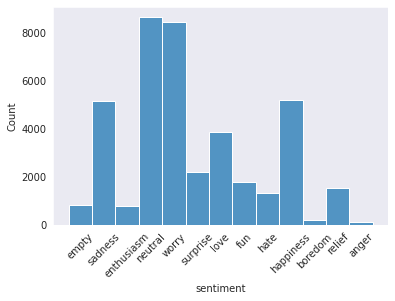

In [4]:
pd.plotting.register_matplotlib_converters()
sns.set_style("dark")
sns.histplot(df['sentiment'])
plt.xticks(rotation=45) 
plt.show()

In [5]:
import re

# 文本清洗函数
# 保留 'sentiment' 为 'empty' 的行，直到下一步再移除
df["cleaned_text"] = df["content"].apply(lambda x: re.sub(r"@[\\w]*", "", str(x)))
df["cleaned_text"] = df["cleaned_text"].apply(lambda x: re.sub(r"[^a-zA-Z']", " ", x))
df["cleaned_text"] = df["cleaned_text"].str.lower().str.strip() 

# 过滤掉标签为 'empty' 和清洗后文本长度过短的行
df_cleaned = df[df['sentiment'] != 'empty'].copy()
df_cleaned = df_cleaned[df_cleaned["cleaned_text"].str.len() > 1].reset_index(drop=True)

print(f"原始行数: {len(df)}")
print(f"清洗后行数: {len(df_cleaned)}")
df_cleaned.head()

原始行数: 40000
清洗后行数: 39170


,tweet_id,sentiment,content,cleaned_text
0,1956967666,sadness,Layin n bed with a headache ughhhh...waitin o...,layin n bed with a headache ughhhh waitin o...
1,1956967696,sadness,Funeral ceremony...gloomy friday...,funeral ceremony gloomy friday
2,1956967789,enthusiasm,wants to hang out with friends SOON!,wants to hang out with friends soon
3,1956968416,neutral,@dannycastillo We want to trade with someone w...,dannycastillo we want to trade with someone wh...
4,1956968477,worry,Re-pinging @ghostridah14: why didn't you go to...,re pinging ghostridah why didn't you go to ...


In [6]:
# 清洗后数据总数与分布验证
# 1. 原始数据总数
original_count = len(df)
# 2. 清洗后数据总数
cleaned_count = len(df_cleaned)
# 3. 统计清洗后各情感类别的数量
sentiment_counts_cleaned = df_cleaned['sentiment'].value_counts()

print("--- 数据总数与情感分布统计 ---")
print(f"原始数据集总行数: {original_count}")
print(f"清洗后数据集总行数: {cleaned_count}")
print("-" * 30)
print("清洗后情感类别分布 (Count):")
print(sentiment_counts_cleaned)

--- 数据总数与情感分布统计 ---
原始数据集总行数: 40000
清洗后数据集总行数: 39170
------------------------------
清洗后情感类别分布 (Count):
neutral       8635
worry         8459
happiness     5209
sadness       5165
love          3842
surprise      2187
fun           1776
relief        1526
hate          1323
enthusiasm     759
boredom        179
anger          110
Name: sentiment, dtype: int64


In [7]:
#导入标签编码器
from sklearn.preprocessing import LabelEncoder

# 定义特征 X 和标签 Y
X = df_cleaned['cleaned_text']
y = df_cleaned['sentiment']

# 标签编码
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 保存类别名称，用于最终报告
class_names = le.classes_ 

print("标签与编码对照表:")
for i, name in enumerate(class_names):
    print(f"{i}: {name}")

标签与编码对照表:
0: anger
1: boredom
2: enthusiasm
3: fun
4: happiness
5: hate
6: love
7: neutral
8: relief
9: sadness
10: surprise
11: worry


In [8]:
# In[4]: 导入数据集划分工具 分层抽样
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y_encoded, 
    test_size=0.2, 
    random_state=42, 
    stratify=y_encoded 
)

# 分层抽样保证训练集和测试集中的类别比例一致

print(f"The sample size of the training set: {len(X_train)}")
print(f"The sample size of the testing set: {len(X_test)}")

The sample size of the training set: 31336
The sample size of the testing set: 7834


In [9]:
#导入 TF-IDF 向量化器
from sklearn.feature_extraction.text import TfidfVectorizer

# 创建 TF-IDF 向量化器实例
# max_features=10000: 限制只考虑前10000个最具区分度的词作为特征
# ngram_range=(1, 2): 同时考虑单个词 (unigram) 和连续两个词 (bigram)
tfidf_vectorizer = TfidfVectorizer(max_features=10000, ngram_range=(1, 2),stop_words='english')

# 在训练集上拟合和转换
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

# 在测试集上仅转换 (使用训练集学习到的词汇表)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print(f"训练集特征矩阵形状 (样本数, 特征数): {X_train_tfidf.shape}")
print(f"测试集特征矩阵形状 (样本数, 特征数): {X_test_tfidf.shape}")

训练集特征矩阵形状 (样本数, 特征数): (31336, 10000)
测试集特征矩阵形状 (样本数, 特征数): (7834, 10000)


In [10]:
feature_names = tfidf_vectorizer.get_feature_names_out()

# 2. 选取要分析的样本索引 (X_train 中的前 5 个)
sample_indices = [0, 1, 2, 3, 4] 

print("=== 针对前五行推文的 TF-IDF 词汇权重分析 ===")

# 循环处理每一条推文
for i in sample_indices:
    # 原始推文内容 (来自 X_train)
    original_text = X_train.iloc[i]
    
    # 获取该推文在 X_train_tfidf 稀疏矩阵中的行向量
    # .getrow(i) 返回的是 SciPy CSR 格式的稀疏行
    feature_vector = X_train_tfidf.getrow(i)
    
    # 提取非零特征的索引和值 (即 TF-IDF 权重)
    # feature_vector.nonzero()[1] 是非零元素的列索引
    feature_indices = feature_vector.nonzero()[1]
    tfidf_scores = feature_vector.data # 对应的 TF-IDF 权重值
    
    # 3. 将索引和权重映射到实际词汇
    tfidf_map = {
        feature_names[index]: score 
        for index, score in zip(feature_indices, tfidf_scores)
    }
    
    # 4. 排序并展示权重最高的词
    # 按权重值（score）降序排序
    sorted_features = sorted(tfidf_map.items(), key=lambda item: item[1], reverse=True)
    
    # 打印结果
    print("-" * 60)
    print(f"推文 #{i} (情感: {y.iloc[i]}):") # 假设 y 是原始情感标签
    print(f"  原始文本: '{original_text}'")
    
    print("\n  TF-IDF 权重最高的 TOP 10 特征:")
    for word, score in sorted_features[:10]:
        # TF-IDF 权重 (Score) 越高，该词对区分该文档越重要
        print(f"    - {word}: {score:.4f}")

=== 针对前五行推文的 TF-IDF 词汇权重分析 ===
------------------------------------------------------------
推文 #0 (情感: sadness):
  原始文本: 'this headache is killing me yet i need to cover some boring police event'

  TF-IDF 权重最高的 TOP 10 特征:
    - police: 0.4484
    - event: 0.4171
    - cover: 0.4130
    - killing: 0.3885
    - boring: 0.3590
    - headache: 0.3363
    - need: 0.2481
------------------------------------------------------------
推文 #1 (情感: sadness):
  原始文本: 'i'm at my saddest right now  i lost my mobile phone earphones  waz feels a little incomplete and i feel the same'

  TF-IDF 权重最高的 TOP 10 特征:
    - waz: 0.4247
    - earphones: 0.4168
    - saddest: 0.3991
    - mobile: 0.3330
    - feels: 0.2987
    - lost: 0.2639
    - phone: 0.2517
    - little: 0.2395
    - right: 0.2224
    - feel: 0.2159
------------------------------------------------------------
推文 #2 (情感: enthusiasm):
  原始文本: 'docbaty good night   sorry i missed you during our morning window   see you at    i suspect'

  TF-ID

In [11]:
# 1. 定义目标权重区间
LOWER_BOUND = 6.0
UPPER_BOUND = 7.0
TOP_N = 10

# 2. 筛选出位于该区间的特征
# 使用布尔索引过滤，找出 IDF score 在 [6.0, 7.0] 范围内的词汇
filtered_df = idf_df[
    (idf_df['idf_score'] >= LOWER_BOUND) & 
    (idf_df['idf_score'] <= UPPER_BOUND)
]

# 3. 按 IDF 权重降序排列
# 降序排列，以便找到区间内权重最高的词
top_filtered_features = filtered_df.sort_values(by='idf_score', ascending=False).head(TOP_N)

print(f"=== 权重在 [{LOWER_BOUND:.1f} - {UPPER_BOUND:.1f}] 区间内的 TOP {TOP_N} 词汇 (按 IDF 降序) ===")
print(top_filtered_features)

NameError: name 'idf_df' is not defined

In [ ]:


# 目标索引：3356、4440和1013
target_indices = [2594, 2619]

# 1. 获取这些索引对应的词
index_to_word = {idx: word for word, idx in tfidf_vectorizer.vocabulary_.items()}

target_words = []
for idx in target_indices:
    if idx in index_to_word:
        target_words.append(index_to_word[idx])
    else:
        target_words.append(f"索引{idx}（不存在）")

print("目标索引对应的词：")
for idx, word in zip(target_indices, target_words):
    print(f"索引 {idx}: {word}")

# 2. 找到包含这些词的样本
sample_indices_list = []
for idx in target_indices:
    if idx not in index_to_word:
        sample_indices_list.append([])
        continue
    # 获取包含该词的所有样本索引
    doc_indices = X_train_tfidf[:, idx].nonzero()[0]
    # 最多取5个样本
    sample_indices = doc_indices[:5] if len(doc_indices) >= 5 else doc_indices
    sample_indices_list.append(sample_indices)

# 3. 可视化每个目标词在其样本中的TF-IDF值（修正错误部分）
plt.figure(figsize=(18, 5))
for i, (idx, word, sample_indices) in enumerate(zip(target_indices, target_words, sample_indices_list)):
    if len(sample_indices) == 0:
        plt.subplot(1, 3, i+1)
        plt.text(0.5, 0.5, f"无包含 '{word}' 的样本", 
                 horizontalalignment='center', verticalalignment='center',
                 fontsize=12)
        plt.xticks([])
        plt.yticks([])
        plt.title(f"索引 {idx}: {word}")
        continue
    
    # 关键修改：获取单个元素的TF-IDF值不需要toarray()
    tfidf_values = [X_train_tfidf[sample_idx, idx] for sample_idx in sample_indices]
    
    # 绘制条形图
    plt.subplot(1, 3, i+1)
    sns.barplot(x=[f"sample {s}" for s in sample_indices], y=tfidf_values, color='skyblue')
    plt.title(f"sample {idx}: {word}\nTF-IDF")
    plt.xlabel("sample index")
    plt.ylabel("TF-IDF value")
    plt.xticks(rotation=45)
    # 添加数值标签
    for j, v in enumerate(tfidf_values):
        plt.text(j, v + 0.01, f"{v:.3f}", ha='center')

plt.tight_layout()
plt.show()

# 4. 展示这三个词在所有样本中的TF-IDF整体分布
plt.figure(figsize=(12, 6))
distribution_data = []
labels = []

for idx, word in zip(target_indices, target_words):
    if idx not in index_to_word:
        continue
    # 获取该词在所有样本中的TF-IDF值（仅非零值）
    all_tfidf = X_train_tfidf[:, idx].toarray().flatten()  # 这里对整个列用toarray()是正确的
    non_zero_tfidf = all_tfidf[all_tfidf > 0]
    distribution_data.append(non_zero_tfidf)
    labels.append(f"sample {idx}: {word}")

sns.boxplot(data=distribution_data)
plt.xticks(range(len(labels)), labels, rotation=45)
plt.title("Comparison of the overall distribution of TF-IDF values of the target word")
plt.ylabel("TF-IDF")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
#favorite (2619): 它的 TF-IDF 权重相对稳定和集中。
#   这意味着当它出现在推文中时，其重要性（TF-IDF 值）通常在一个可预测的范围内，对模型来说是一个可靠的信号。
#   fan (2594): 它的 TF-IDF 权重波动较大，偶尔会出现极高值。这意味着它可能在某些推文中是唯一的关键词（高 TF），
#   但在其他推文中只是众多词汇之一。"""

In [12]:
# In[6]: 导入朴素贝叶斯模型
from sklearn.naive_bayes import MultinomialNB

# 创建并训练模型
mnb_model = MultinomialNB()
mnb_model.fit(X_train_tfidf, y_train)

# 在测试集上进行预测
y_pred = mnb_model.predict(X_test_tfidf)

print("模型训练完成，开始评估...")

模型训练完成，开始评估...


--- 多类别分类报告 ---
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        22
     boredom       0.00      0.00      0.00        36
  enthusiasm       0.00      0.00      0.00       152
         fun       0.50      0.00      0.01       355
   happiness       0.35      0.23      0.28      1042
        hate       0.00      0.00      0.00       265
        love       0.53      0.23      0.32       768
     neutral       0.30      0.55      0.39      1727
      relief       0.00      0.00      0.00       305
     sadness       0.36      0.09      0.15      1033
    surprise       0.00      0.00      0.00       437
       worry       0.30      0.59      0.40      1692

    accuracy                           0.32      7834
   macro avg       0.19      0.14      0.13      7834
weighted avg       0.30      0.32      0.26      7834



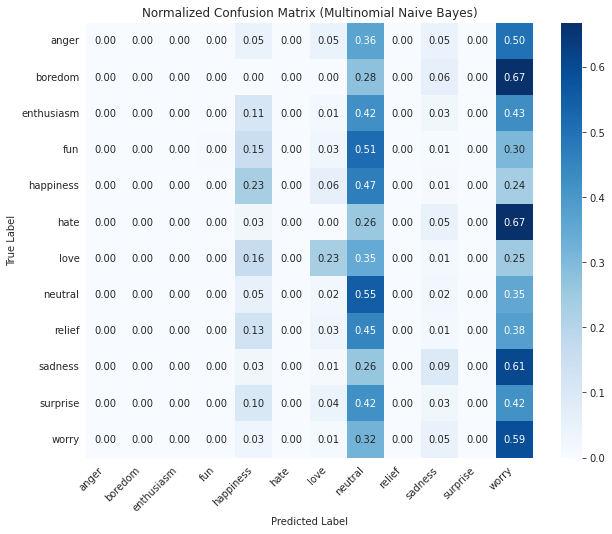

In [14]:
# In[7]: 导入评估工具
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# 生成分类报告
print("--- 多类别分类报告 ---")
# zero_division=0: 避免某些类别上没有预测结果时报错
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

# 生成混淆矩阵
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] # 归一化

# 可视化混淆矩阵 
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues",
    xticklabels=class_names, 
    yticklabels=class_names
)
plt.title('Normalized Confusion Matrix (Multinomial Naive Bayes)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.show()

In [15]:
#添加alpha平滑
alpha_list = [0.01, 0.1, 0.5, 1.0, 2.0]
for alpha in alpha_list:
    temp_model = MultinomialNB(alpha=alpha)
    temp_model.fit(X_train_tfidf, y_train)
    temp_pred = temp_model.predict(X_test_tfidf)
    accuracy = (temp_pred == y_test).mean()
    print(f"alpha={alpha} ，accuracy：{accuracy:.4f}")

alpha=0.01 ，accuracy：0.3113
alpha=0.1 ，accuracy：0.3166
alpha=0.5 ，accuracy：0.3213
alpha=1.0 ，accuracy：0.3158
alpha=2.0 ，accuracy：0.3141


--- 多类别分类报告（alpha=0.5） ---
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        22
     boredom       0.00      0.00      0.00        36
  enthusiasm       0.00      0.00      0.00       152
         fun       0.25      0.00      0.01       355
   happiness       0.33      0.27      0.29      1042
        hate       0.60      0.01      0.02       265
        love       0.47      0.26      0.34       768
     neutral       0.31      0.54      0.39      1727
      relief       0.00      0.00      0.00       305
     sadness       0.35      0.16      0.22      1033
    surprise       0.25      0.00      0.00       437
       worry       0.30      0.55      0.39      1692

    accuracy                           0.32      7834
   macro avg       0.24      0.15      0.14      7834
weighted avg       0.32      0.32      0.27      7834



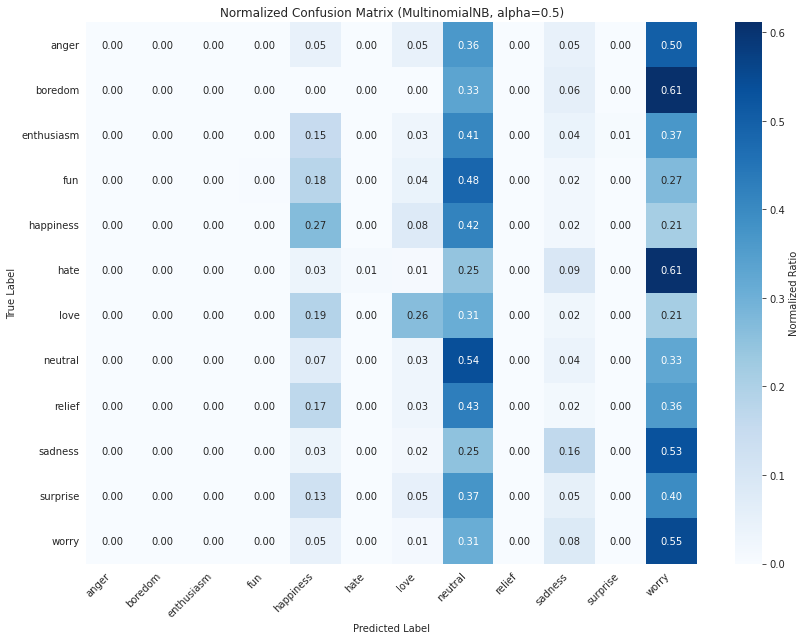

In [16]:
mnb_model = MultinomialNB(alpha=0.5)  # 关键改动：新增alpha参数=0.5

# 训练模型（其余步骤不变）
mnb_model.fit(X_train_tfidf, y_train)

# 在测试集上进行预测
y_pred = mnb_model.predict(X_test_tfidf)


# 生成分类报告（保留zero_division=0，避免小众类别报错）
print("--- 多类别分类报告（alpha=0.5） ---")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

# 生成混淆矩阵并归一化
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# 可视化混淆矩阵（样式微调，更易读）
plt.figure(figsize=(12, 9))  # 稍微放大图，避免标签拥挤
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues",
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio"}  # 新增色条标签，更清晰
)
plt.title('Normalized Confusion Matrix (MultinomialNB, alpha=0.5)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()  # 自动调整布局，避免标签被截断
plt.show()


--- Multi-class Classification Report (Logistic Regression + Class Weight) ---
              precision    recall  f1-score   support

       anger       0.00      0.00      0.00        22
     boredom       0.05      0.22      0.08        36
  enthusiasm       0.03      0.11      0.04       152
         fun       0.11      0.24      0.15       355
   happiness       0.35      0.25      0.29      1042
        hate       0.20      0.39      0.26       265
        love       0.44      0.42      0.43       768
     neutral       0.39      0.25      0.30      1727
      relief       0.11      0.22      0.14       305
     sadness       0.33      0.29      0.31      1033
    surprise       0.11      0.17      0.13       437
       worry       0.43      0.23      0.30      1692

    accuracy                           0.26      7834
   macro avg       0.21      0.23      0.20      7834
weighted avg       0.34      0.26      0.28      7834



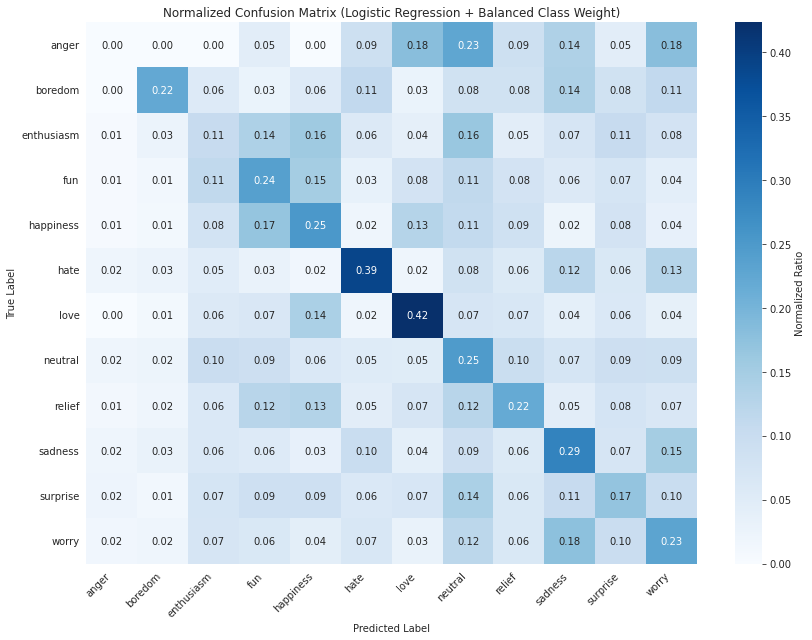

In [17]:
from sklearn.linear_model import LogisticRegression  # 朴素贝叶斯无class_weight，换逻辑回归（效果更好）
# ===================== 类别权重调整 =====================
# 注意：MultinomialNB 没有class_weight参数，换逻辑回归（文本分类效果优于朴素贝叶斯，且支持权重）
lr_model = LogisticRegression(
    class_weight='balanced',  # 核心：自动平衡类别权重
    max_iter=1000,            # 增加迭代次数，保证收敛
    random_state=42
)

# 训练模型
lr_model.fit(X_train_tfidf, y_train)

# 预测
y_pred = lr_model.predict(X_test_tfidf)

# 评估
print("--- Multi-class Classification Report (Logistic Regression + Class Weight) ---")
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

# 混淆矩阵可视化（全英文）
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(12, 9))
sns.heatmap(
    cm_normalized, 
    annot=True, 
    fmt=".2f", 
    cmap="Blues",
    xticklabels=class_names, 
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio"}
)
plt.title('Normalized Confusion Matrix (Logistic Regression + Balanced Class Weight)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# 优化逻辑回归参数：减小C，增强正则化，避免过拟合小众类
lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,                # 增加迭代次数保证收敛
    C=0.1,                        # 核心调整：C越小，正则化越强，避免模型过度关注小众类的噪声
    random_state=42
)

# 重新训练+评估
lr_model.fit(X_train_tfidf, y_train)
y_pred = lr_model.predict(X_test_tfidf)
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

              precision    recall  f1-score   support

       anger       0.00      0.05      0.00        22
     boredom       0.03      0.36      0.06        36
  enthusiasm       0.04      0.19      0.06       152
         fun       0.13      0.28      0.18       355
   happiness       0.36      0.21      0.26      1042
        hate       0.22      0.42      0.29       265
        love       0.47      0.41      0.44       768
     neutral       0.41      0.22      0.29      1727
      relief       0.12      0.24      0.16       305
     sadness       0.35      0.25      0.29      1033
    surprise       0.12      0.19      0.14       437
       worry       0.44      0.17      0.24      1692

    accuracy                           0.24      7834
   macro avg       0.22      0.25      0.20      7834
weighted avg       0.35      0.24      0.27      7834



In [19]:
!pip install imbalanced-learn  # 用于SMOTE过采样

Defaulting to user installation because normal site-packages is not writeable


In [20]:
from imblearn.over_sampling import SMOTE
# Initialize SMOTE
smote = SMOTE(
    random_state=42,
    sampling_strategy='not majority',
    k_neighbors=5
)

# Apply SMOTE to training set ONLY
print("📈 Class distribution BEFORE SMOTE:")
train_dist = pd.Series(y_train).value_counts().sort_index()
for idx, cnt in train_dist.items():
    print(f"  {class_names[idx]}: {cnt}")

X_train_tfidf_smote, y_train_smote = smote.fit_resample(X_train_tfidf, y_train)

print("\n📈 Class distribution AFTER SMOTE:")
train_dist_smote = pd.Series(y_train_smote).value_counts().sort_index()
for idx, cnt in train_dist_smote.items():
    print(f"  {class_names[idx]}: {cnt}")

print(f"\n✅ SMOTE applied - New training shape: {X_train_tfidf_smote.shape}")


📈 Class distribution BEFORE SMOTE:
  anger: 88
  boredom: 143
  enthusiasm: 607
  fun: 1421
  happiness: 4167
  hate: 1058
  love: 3074
  neutral: 6908
  relief: 1221
  sadness: 4132
  surprise: 1750
  worry: 6767

📈 Class distribution AFTER SMOTE:
  anger: 6908
  boredom: 6908
  enthusiasm: 6908
  fun: 6908
  happiness: 6908
  hate: 6908
  love: 6908
  neutral: 6908
  relief: 6908
  sadness: 6908
  surprise: 6908
  worry: 6908

✅ SMOTE applied - New training shape: (82896, 10000)


In [21]:
# Train Logistic Regression with balanced weights
lr_model = LogisticRegression(
    max_iter=2000,
    C=0.5,
    random_state=42
)

# Fit model
print("🚀 Training model...")
lr_model.fit(X_train_tfidf_smote, y_train_smote)

# Predict on test set
y_pred = lr_model.predict(X_test_tfidf)
print("✅ Model training and prediction completed!")

🚀 Training model...
✅ Model training and prediction completed!


In [22]:
# Generate classification report
report = classification_report(
    y_test, 
    y_pred, 
    target_names=class_names, 
    zero_division=0,
    output_dict=True
)

# Print formatted report
print("📊 Classification Report (Logistic Regression + SMOTE)\n")
# Convert to DataFrame for better display in Notebook
report_df = pd.DataFrame(report).transpose()
report_df = report_df.round(4)  # Round to 4 decimal places
display(report_df)  # Use display() for pretty table in Notebook

📊 Classification Report (Logistic Regression + SMOTE)



,precision,recall,f1-score,support
anger,0.0000,0.0000,0.0000,22.0000
boredom,0.0496,0.1944,0.0791,36.0000
enthusiasm,0.0182,0.0724,0.0291,152.0000
fun,0.1241,0.2000,0.1532,355.0000
happiness,0.3517,0.3119,0.3306,1042.0000
hate,0.1921,0.3283,0.2423,265.0000
love,0.4448,0.4141,0.4289,768.0000
neutral,0.3463,0.2119,0.2629,1727.0000
relief,0.1148,0.1836,0.1412,305.0000
sadness,0.3180,0.2682,0.2910,1033.0000


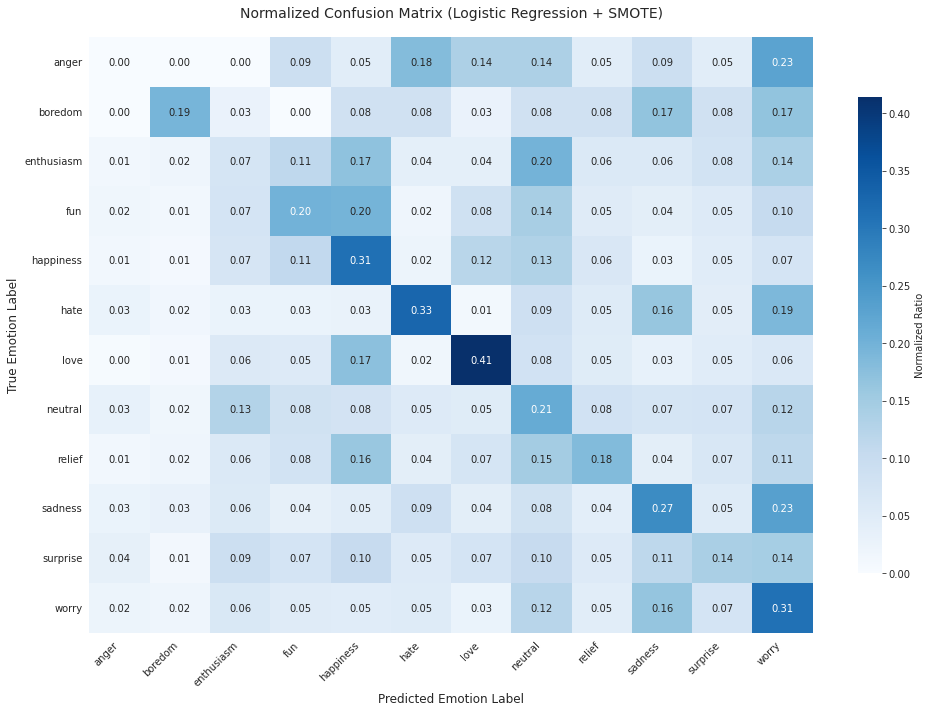

In [23]:
# Generate and normalize confusion matrix
cm = confusion_matrix(y_test, y_pred)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

# Plot heatmap
plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Normalized Ratio", "shrink": 0.8}
)

# Customize plot
plt.title('Normalized Confusion Matrix (Logistic Regression + SMOTE)', fontsize=14, pad=20)
plt.ylabel('True Emotion Label', fontsize=12)
plt.xlabel('Predicted Emotion Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Show plot
plt.show()

In [24]:
# Calculate key metrics
overall_accuracy = (y_pred == y_test).mean()
macro_f1 = report['macro avg']['f1-score']
weighted_f1 = report['weighted avg']['f1-score']

# Create summary table
summary = pd.DataFrame({
    "Metric": ["Overall Accuracy", "Macro F1 Score", "Weighted F1 Score"],
    "Value": [round(overall_accuracy, 4), round(macro_f1, 4), round(weighted_f1, 4)]
})

print("🏆 Key Performance Metrics\n")
display(summary)

# Print class-wise F1 scores (sorted)
f1_scores = {class_names[i]: report[class_names[i]]['f1-score'] for i in range(len(class_names))}
f1_df = pd.DataFrame(list(f1_scores.items()), columns=['Emotion', 'F1 Score']).sort_values(by='F1 Score', ascending=False)
print("\n🥇 Class-wise F1 Scores (Sorted)\n")
display(f1_df)

🏆 Key Performance Metrics



,Metric,Value
0,Overall Accuracy,0.2686
1,Macro F1 Score,0.2029
2,Weighted F1 Score,0.2865



🥇 Class-wise F1 Scores (Sorted)



,Emotion,F1 Score
6,love,0.428860
11,worry,0.349301
4,happiness,0.330621
9,sadness,0.290966
7,neutral,0.262931
5,hate,0.242340
3,fun,0.153182
8,relief,0.141236
10,surprise,0.127482
1,boredom,0.079096


Negative: ['worry', 'sadness', 'hate', 'boredom', 'anger']
Positive: ['enthusiasm', 'fun', 'happiness', 'love', 'relief', 'surprise']

二分类样本分布:
1    15299
0    15236
Name: binary_label, dtype: int64
Positive样本数: 15299
Negative样本数: 15236

--- 二分类模型评估结果 ---
准确率: 0.7488

分类报告:
              precision    recall  f1-score   support

    Negative       0.74      0.76      0.75      3047
    Positive       0.76      0.73      0.75      3060

    accuracy                           0.75      6107
   macro avg       0.75      0.75      0.75      6107
weighted avg       0.75      0.75      0.75      6107



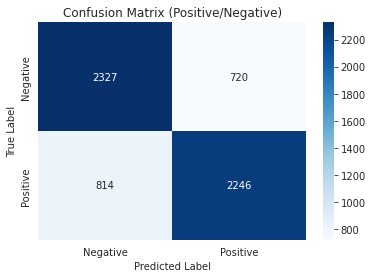

In [25]:
# ========== Step 1: 定义正负情感映射 ==========
# 定义Negative情感列表
negative_emotions = ['worry', 'sadness', 'hate', 'boredom', 'anger']
positive_emotions = [emo for emo in class_names if emo not in negative_emotions + ['neutral']]
# 定义Positive情感列表（排除negative和neutral）

print("Negative:", negative_emotions)
print("Positive:", positive_emotions)

# ========== Step 2: 处理标签（生成二分类标签） ==========
# 先筛选数据：剔除neutral，只保留positive/negative
df_binary = df_cleaned[df_cleaned['sentiment'] != 'neutral'].copy()

# 生成二分类标签：1=Positive，0=Negative
df_binary['binary_label'] = df_binary['sentiment'].apply(
    lambda x: 1 if x in positive_emotions else 0
)

# 查看二分类样本分布
print("\n二分类样本分布:")
print(df_binary['binary_label'].value_counts())
print(f"Positive样本数: {len(df_binary[df_binary['binary_label']==1])}")
print(f"Negative样本数: {len(df_binary[df_binary['binary_label']==0])}")

# ========== Step 3: 数据集拆分+特征工程（复用TF-IDF） ==========
X_binary = df_binary['cleaned_text']
y_binary = df_binary['binary_label']

# 分层拆分（保证正负样本比例一致）
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_binary, y_binary, test_size=0.2, random_state=42, stratify=y_binary
)

# 复用之前的TF-IDF向量化器（或重新训练）
tfidf_bin = TfidfVectorizer(max_features=10000, ngram_range=(1,2))
X_train_tfidf_bin = tfidf_bin.fit_transform(X_train_bin)
X_test_tfidf_bin = tfidf_bin.transform(X_test_bin)

# ========== Step 4: 训练二分类模型（逻辑回归） ==========
lr_binary = LogisticRegression(
    class_weight='balanced',  # 平衡二分类样本
    max_iter=2000,
    random_state=42
)
lr_binary.fit(X_train_tfidf_bin, y_train_bin)
y_pred_bin = lr_binary.predict(X_test_tfidf_bin)

# ========== Step 5: 评估二分类结果 ==========
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("\n--- 二分类模型评估结果 ---")
print(f"准确率: {accuracy_score(y_test_bin, y_pred_bin):.4f}")
print("\n分类报告:")
print(classification_report(y_test_bin, y_pred_bin, target_names=['Negative', 'Positive']))

# 混淆矩阵可视化
cm_bin = confusion_matrix(y_test_bin, y_pred_bin)
plt.figure(figsize=(6,4))
sns.heatmap(
    cm_bin, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)
plt.title('Confusion Matrix (Positive/Negative)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

🔍 Emotion Category Mapping:
Negative emotions: ['worry', 'sadness', 'hate', 'boredom', 'anger']
Neutral emotion: ['neutral']
Positive emotions: ['enthusiasm', 'fun', 'happiness', 'love', 'relief', 'surprise']

📊 3-Class Dataset Distribution:
Negative: 15236 samples
Neutral: 8635 samples
Positive: 15299 samples

📝 Dataset Split Result:
Training set size: 31336
Test set size: 7834

🔤 TF-IDF Feature Shape:
Training features: (31336, 10000) (samples, features)
Test features: (7834, 10000) (samples, features)

🚀 Training 3-Class Logistic Regression Model...

🏆 3-Class Classification Results:
Overall Accuracy: 0.5780

📋 Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.63      0.64      3047
     Neutral       0.38      0.48      0.42      1727
    Positive       0.67      0.58      0.62      3060

    accuracy                           0.58      7834
   macro avg       0.56      0.56      0.56      7834
weighted avg       0

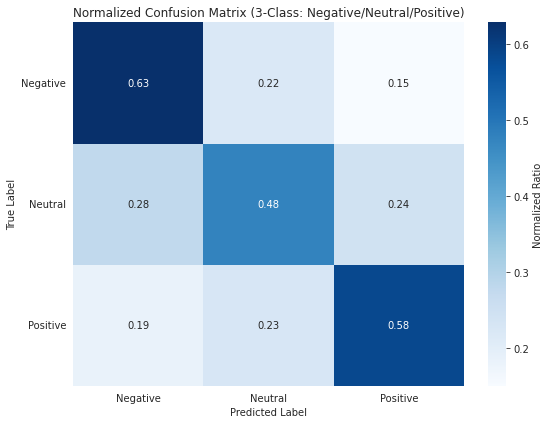


📈 Key Performance Metrics (3-Class):


,Metric,Value
0,Overall Accuracy,0.5780
1,Negative F1,0.6371
2,Neutral F1,0.4200
3,Positive F1,0.6242


In [26]:

# ===================== Step 1: Define Emotion Categories =====================
# Define negative/neutral/positive emotion lists
negative_emotions = ['worry', 'sadness', 'hate', 'boredom', 'anger']  # Your defined negative
neutral_emotion = ['neutral']  # Neutral category
positive_emotions = [emo for emo in class_names if emo not in negative_emotions + neutral_emotion]  # Remaining as positive

# Print category mapping (for verification)
print("🔍 Emotion Category Mapping:")
print(f"Negative emotions: {negative_emotions}")
print(f"Neutral emotion: {neutral_emotion}")
print(f"Positive emotions: {positive_emotions}")

# ===================== Step 2: Create 3-Class Labels =====================
# Copy cleaned dataset to avoid modifying original data
df_tri = df_cleaned.copy()

# Map original emotions to 3-class labels:
# 0 = Negative, 1 = Neutral, 2 = Positive
df_tri['tri_label'] = df_tri['sentiment'].apply(
    lambda x: 0 if x in negative_emotions 
              else 1 if x in neutral_emotion 
              else 2
)

# Check 3-class distribution (critical for imbalance check)
print("\n📊 3-Class Dataset Distribution:")
class_dist = df_tri['tri_label'].value_counts().sort_index()
class_names_tri = ['Negative', 'Neutral', 'Positive']  # Corresponding to 0/1/2
for idx, cnt in class_dist.items():
    print(f"{class_names_tri[idx]}: {cnt} samples")

# ===================== Step 3: Train-Test Split (Stratified) =====================
# Define features (cleaned text) and labels (3-class)
X_tri = df_tri['cleaned_text']
y_tri = df_tri['tri_label']

# Split dataset (80% train, 20% test) with stratification (keep class ratio)
X_train_tri, X_test_tri, y_train_tri, y_test_tri = train_test_split(
    X_tri, y_tri,
    test_size=0.2,
    random_state=42,
    stratify=y_tri  # Critical for balanced split in 3-class task
)

print("\n📝 Dataset Split Result:")
print(f"Training set size: {len(X_train_tri)}")
print(f"Test set size: {len(X_test_tri)}")

# ===================== Step 4: TF-IDF Vectorization =====================
# Initialize TF-IDF (reuse your optimal parameters)
tfidf_tri = TfidfVectorizer(
    max_features=10000,  # Top 10k most discriminative words
    ngram_range=(1, 2)   # Unigram + Bigram for better semantic capture
)

# Fit on training set only (avoid data leakage)
X_train_tfidf_tri = tfidf_tri.fit_transform(X_train_tri)
# Transform test set with training vocabulary
X_test_tfidf_tri = tfidf_tri.transform(X_test_tri)

print("\n🔤 TF-IDF Feature Shape:")
print(f"Training features: {X_train_tfidf_tri.shape} (samples, features)")
print(f"Test features: {X_test_tfidf_tri.shape} (samples, features)")

# ===================== Step 5: Train Logistic Regression Model =====================
# Initialize model with balanced class weight (combat imbalance)
lr_tri = LogisticRegression(
    class_weight='balanced',  # Auto-adjust weight for imbalanced classes
    max_iter=2000,            # Increase iterations to ensure convergence
    random_state=42           # Reproducibility
)

# Train model on TF-IDF features
print("\n🚀 Training 3-Class Logistic Regression Model...")
lr_tri.fit(X_train_tfidf_tri, y_train_tri)

# Predict on test set
y_pred_tri = lr_tri.predict(X_test_tfidf_tri)

# ===================== Step 6: Evaluate Model Performance =====================
# Calculate overall accuracy
overall_accuracy = accuracy_score(y_test_tri, y_pred_tri)

# Print evaluation results
print("\n🏆 3-Class Classification Results:")
print(f"Overall Accuracy: {overall_accuracy:.4f}")
print("\n📋 Detailed Classification Report:")
print(classification_report(
    y_test_tri, y_pred_tri,
    target_names=class_names_tri,  # Map 0/1/2 to readable names
    zero_division=0               # Avoid error for rare classes
))

# ===================== Step 7: Visualize Confusion Matrix =====================
# Generate confusion matrix
cm_tri = confusion_matrix(y_test_tri, y_pred_tri)
# Normalize to ratio (easier to compare across classes)
cm_tri_normalized = cm_tri.astype('float') / cm_tri.sum(axis=1)[:, np.newaxis]

# Plot normalized confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_tri_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names_tri,
    yticklabels=class_names_tri,
    cbar_kws={"label": "Normalized Ratio"}
)
plt.title('Normalized Confusion Matrix (3-Class: Negative/Neutral/Positive)')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# ===================== Step 8: Key Metric Summary =====================
# Create summary table for report
summary_tri = pd.DataFrame({
    "Metric": ["Overall Accuracy", "Negative F1", "Neutral F1", "Positive F1"],
    "Value": [
        round(overall_accuracy, 4),
        round(classification_report(y_test_tri, y_pred_tri, output_dict=True)['0']['f1-score'], 4),
        round(classification_report(y_test_tri, y_pred_tri, output_dict=True)['1']['f1-score'], 4),
        round(classification_report(y_test_tri, y_pred_tri, output_dict=True)['2']['f1-score'], 4)
    ]
})

print("\n📈 Key Performance Metrics (3-Class):")
display(summary_tri)

🔍 Top 10 Positive Keywords (权重越大，越代表积极):


,word,weight
4862,love,5.0124
3193,happy,4.7305
3142,haha,4.4111
639,awesome,4.2522
3043,great,3.8533
7829,thanks,3.7752
224,amazing,3.7338
2430,finally,3.5764
2698,fun,3.4676
1676,cute,3.3464



🔍 Top 10 Negative Keywords (权重越小，越代表消极):


,word,weight
6870,sad,-6.2782
3245,hate,-5.2228
7441,sorry,-4.8424
7177,sick,-4.1141
5783,not,-3.6608
686,bad,-3.6434
7633,sucks,-3.6326
6456,poor,-3.5831
5232,missing,-3.3466
3696,hurts,-3.2823


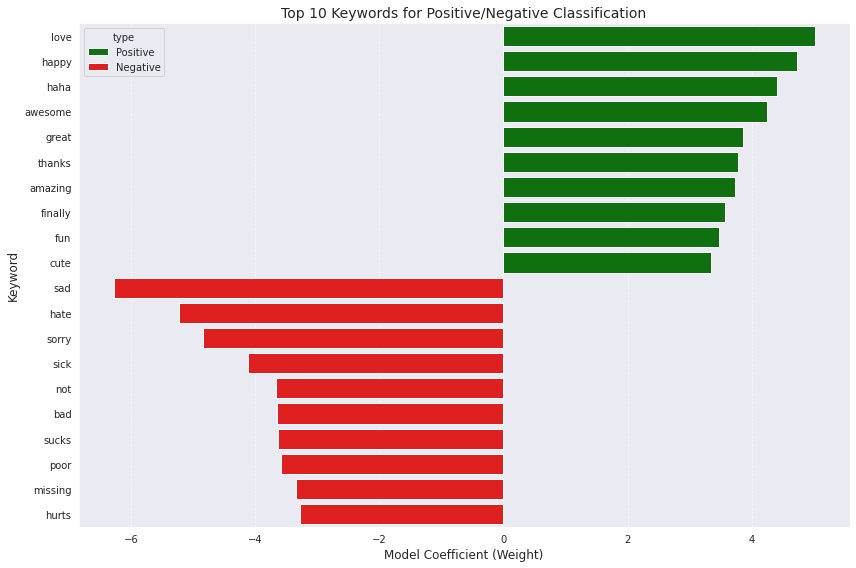

In [27]:
# ===================== Step 1: 提取TF-IDF词汇表与模型系数 =====================
# 获取TF-IDF的词汇表（词→索引的映射）
vocab = tfidf_bin.vocabulary_  # 格式：{"word": index}
# 反转映射：索引→词
index_to_word = {idx: word for word, idx in vocab.items()}

# 获取逻辑回归模型的系数（对应每个词的权重）
# 注意：二分类模型的系数形状为 (1, 特征数)，取第0维即可
coef = lr_binary.coef_[0]

# ===================== Step 2: 关联“词”与“权重” =====================
# 创建DataFrame存储词和对应的权重
word_weights = pd.DataFrame({
    "word": [index_to_word[idx] for idx in range(len(coef))],
    "weight": coef
})

# ===================== Step 3: 提取Top10 Positive/Negative关键词 =====================
# Top10 Positive词（权重最大）
top10_positive = word_weights.sort_values(by="weight", ascending=False).head(10)
# Top10 Negative词（权重最小）
top10_negative = word_weights.sort_values(by="weight", ascending=True).head(10)

# 打印结果
print("🔍 Top 10 Positive Keywords (权重越大，越代表积极):")
display(top10_positive[["word", "weight"]].round(4))

print("\n🔍 Top 10 Negative Keywords (权重越小，越代表消极):")
display(top10_negative[["word", "weight"]].round(4))

# ===================== Step 4: 可视化关键词（更直观） =====================
# 合并正负关键词，用于绘图
top_words = pd.concat([
    top10_positive.assign(type="Positive"),
    top10_negative.assign(type="Negative")
])

# 水平条形图可视化
plt.figure(figsize=(12, 8))
sns.barplot(
    data=top_words,
    x="weight",
    y="word",
    hue="type",
    palette={"Positive": "green", "Negative": "red"},
    dodge=False  # 避免正负词重叠
)
plt.title("Top 10 Keywords for Positive/Negative Classification", fontsize=14)
plt.xlabel("Model Coefficient (Weight)", fontsize=12)
plt.ylabel("Keyword", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()